# MLP (deep learning) classifier: binary and multiclass

Uses the files from the preprocessing notebook (`processed/`). Trains two Keras MLPs:
1. **Binary** (`label`): normal vs attack.
2. **Multiclass**: the classes defined by `CLASS_SCHEME` in the preprocessing notebook.

Everything is evaluated on the **validation set**, with the same metrics as the Random Forest notebook, so the two can be compared directly in section 8.

Needs TensorFlow: `%pip install tensorflow` (Python 3.12 is supported).

## 1. Imports

In [1]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

model = keras.Sequential([
    keras.layers.Dense(10, activation="relu", input_shape=(5,)),
    keras.layers.Dense(1, activation="sigmoid")
])

print("Keras model created successfully!")
model.summary()

TensorFlow version: 2.21.0
Keras version: 3.15.1
Keras model created successfully!


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import keras
from keras import layers
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [4]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

HIDDEN_UNITS = (128, 64, 32)   # three hidden layers
DROPOUT = 0.3
LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 60                    # early stopping usually ends training much sooner
PATIENCE = 8                   # stop after this many epochs without validation improvement

keras.utils.set_random_seed(SEED)

## 3. Load the processed data

In [5]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype("int32"), data["y_bin_val"].astype("int32")
ym_train, ym_val = data["y_multi_train"].astype("int32"), data["y_multi_val"].astype("int32")
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape, "  classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)   classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Model and training helpers

Each hidden block is Dense, BatchNorm, ReLU, Dropout. Early stopping keeps the weights from the best validation epoch, and the learning rate is halved when validation loss stalls. Class weights from `meta.json` stop the model from ignoring the smaller classes.

In [6]:
def build_mlp(n_in, n_out, binary):
    inputs = keras.Input(shape=(n_in,))
    x = inputs
    for units in HIDDEN_UNITS:
        x = layers.Dense(units, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(DROPOUT)(x)
    if binary:
        outputs = layers.Dense(1, activation="sigmoid")(x)
        loss = "binary_crossentropy"
        metrics = [keras.metrics.AUC(name="auc")]
    else:
        outputs = layers.Dense(n_out, activation="softmax")(x)
        loss = "sparse_categorical_crossentropy"
        metrics = ["accuracy"]
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def train(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Binary MLP (normal vs attack)

In [7]:
mlp_bin = build_mlp(n_features, 1, binary=True)
mlp_bin.summary()
hist_bin = train(mlp_bin, X_train, yb_train, X_val, yb_val, cw_bin)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,161 (63.13 KB)

 Trainable params: 15,713 (61.38 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/60
274/274 - 4s - 15ms/step - auc: 0.9475 - loss: 0.2889 - val_auc: 0.9839 - val_loss: 0.1633 - learning_rate: 0.0010
Epoch 2/60
274/274 - 1s - 5ms/step - auc: 0.9746 - loss: 0.2010 - val_auc: 0.9873 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 5ms/step - auc: 0.9791 - loss: 0.1808 - val_auc: 0.9884 - val_loss: 0.1446 - learning_rate: 0.0010
Epoch 4/60
274/274 - 1s - 5ms/step - auc: 0.9814 - loss: 0.1699 - val_auc: 0.9891 - val_loss: 0.1397 - learning_rate: 0.0010
Epoch 5/60
274/274 - 1s - 5ms/step - auc: 0.9828 - loss: 0.1627 - val_auc: 0.9897 - val_loss: 0.1320 - learning_rate: 0.0010
Epoch 6/60
274/274 - 1s - 5ms/step - auc: 0.9836 - loss: 0.1586 - val_auc: 0.9901 - val_loss: 0.1286 - learning_rate: 0.0010
Epoch 7/60
274/274 - 1s - 5ms/step - auc: 0.9842 - loss: 0.1558 - val_auc: 0.9903 - val_loss: 0.1268 - learning_rate: 0.0010
Epoch 8/60
274/274 - 1s - 5ms/step - auc: 0.9846 - loss: 0.1530 - val_auc: 0.9905 - val_loss: 0.1206 - learning_rate: 0.0010

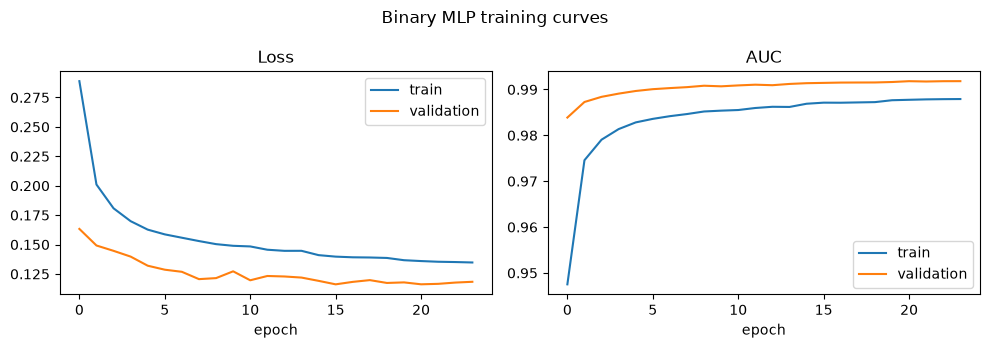

              precision    recall  f1-score   support

      Normal     0.8619    0.9596    0.9082     11200
      Attack     0.9800    0.9279    0.9532     23869

    accuracy                         0.9380     35069
   macro avg     0.9210    0.9437    0.9307     35069
weighted avg     0.9423    0.9380    0.9388     35069

ROC-AUC:              0.9916
False positive rate:  0.0404  (452 normal flows flagged as attacks)
False negative rate:  0.0721  (1722 attacks missed)


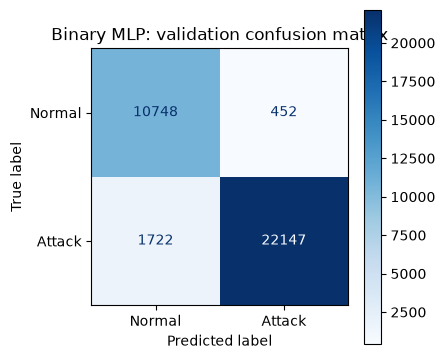

In [8]:
plot_history(hist_bin, "auc", "Binary MLP training curves")

proba_bin = mlp_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)

print(classification_report(yb_val, pred_bin, target_names=["Normal", "Attack"], digits=4))
tn, fp, fn, tp = confusion_matrix(yb_val, pred_bin).ravel()
fpr = fp / (fp + tn)
print(f"ROC-AUC:              {roc_auc_score(yb_val, proba_bin):.4f}")
print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
print(f"False negative rate:  {fn / (fn + tp):.4f}  ({fn} attacks missed)")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    yb_val, pred_bin, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
ax.set_title("Binary MLP: validation confusion matrix")
plt.tight_layout()
plt.show()

### Optional: tune the alert threshold

In [9]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (proba_bin >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_val, p, labels=[0, 1]).ravel()
    rows.append({"threshold": t,
                 "precision": precision_score(yb_val, p, zero_division=0),
                 "recall": recall_score(yb_val, p),
                 "f1": f1_score(yb_val, p),
                 "false_pos_rate": fp_ / (fp_ + tn_)})
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,false_pos_rate
0,0.3,0.9523,0.9793,0.9656,0.1046
1,0.4,0.9739,0.9460,0.9597,0.0539
2,0.5,0.9800,0.9279,0.9532,0.0404
3,0.6,0.9879,0.9023,0.9432,0.0235
4,0.7,0.9904,0.8806,0.9323,0.0182
5,0.8,0.9929,0.8596,0.9215,0.0131
6,0.9,0.9968,0.8169,0.8980,0.0055


## 6. Multiclass MLP

In [10]:
mlp_multi = build_mlp(n_features, n_classes, binary=False)
hist_multi = train(mlp_multi, X_train, ym_train, X_val, ym_val, cw_multi)

Epoch 1/60
274/274 - 4s - 14ms/step - accuracy: 0.5824 - loss: 1.3009 - val_accuracy: 0.7233 - val_loss: 0.7505 - learning_rate: 0.0010
Epoch 2/60
274/274 - 1s - 5ms/step - accuracy: 0.6791 - loss: 1.0380 - val_accuracy: 0.7426 - val_loss: 0.6646 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 5ms/step - accuracy: 0.6992 - loss: 0.9704 - val_accuracy: 0.7599 - val_loss: 0.6245 - learning_rate: 0.0010
Epoch 4/60
274/274 - 1s - 5ms/step - accuracy: 0.7119 - loss: 0.9277 - val_accuracy: 0.7649 - val_loss: 0.6117 - learning_rate: 0.0010
Epoch 5/60
274/274 - 2s - 6ms/step - accuracy: 0.7213 - loss: 0.8962 - val_accuracy: 0.7714 - val_loss: 0.5898 - learning_rate: 0.0010
Epoch 6/60
274/274 - 1s - 5ms/step - accuracy: 0.7272 - loss: 0.8762 - val_accuracy: 0.7772 - val_loss: 0.5689 - learning_rate: 0.0010
Epoch 7/60
274/274 - 1s - 5ms/step - accuracy: 0.7323 - loss: 0.8592 - val_accuracy: 0.7766 - val_loss: 0.5672 - learning_rate: 0.0010
Epoch 8/60
274/274 - 2s - 6ms/step - accuracy: 0.7384 

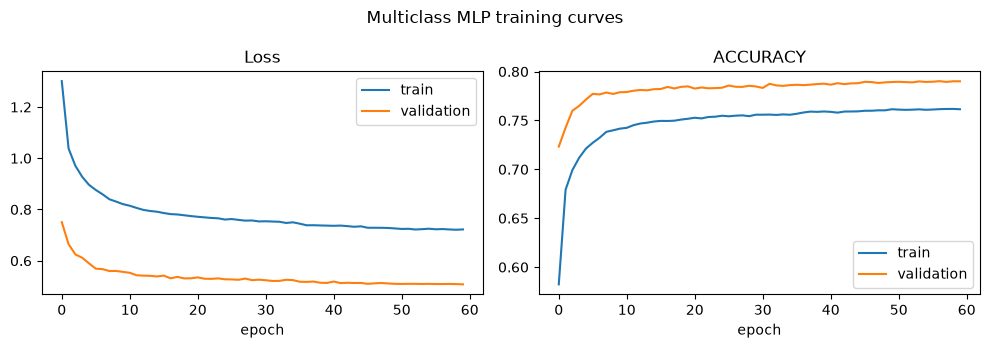

                precision    recall  f1-score   support

        Normal     0.9993    0.8448    0.9156     11200
           DoS     0.3297    0.8088    0.4684      2453
Reconnaissance     0.7850    0.8123    0.7984      2099
       Fuzzers     0.6481    0.8598    0.7391      3637
      Exploits     0.8584    0.4838    0.6188      6678
       Generic     0.9999    0.9801    0.9899      8000
         Other     0.3636    0.3553    0.3594      1002

      accuracy                         0.7900     35069
     macro avg     0.7120    0.7350    0.6985     35069
  weighted avg     0.8583    0.7900    0.8035     35069

macro F1:    0.6985
weighted F1: 0.8035


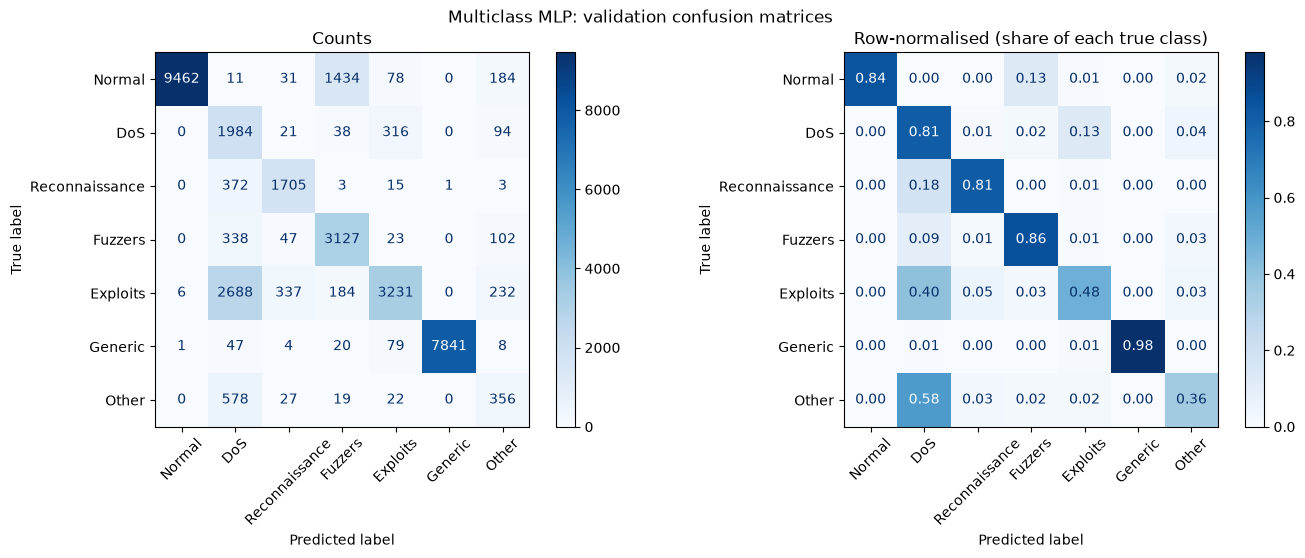

In [11]:
plot_history(hist_multi, "accuracy", "Multiclass MLP training curves")

pred_multi = mlp_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
labels = list(range(n_classes))

print(classification_report(ym_val, pred_multi, labels=labels, target_names=class_names,
                            digits=4, zero_division=0))
print("macro F1:    %.4f" % f1_score(ym_val, pred_multi, average="macro"))
print("weighted F1: %.4f" % f1_score(ym_val, pred_multi, average="weighted"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
axes[1].set_title("Row-normalised (share of each true class)")
plt.suptitle("Multiclass MLP: validation confusion matrices")
plt.tight_layout()
plt.show()

## 7. Detection rate by attack type

Was the flow flagged as an attack at all, and was it given the right type? For the Normal row, the first column is the false alarm rate.

In [12]:
flagged = pred_multi != 0          # class 0 is Normal
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                 "correct type (%)": round(100 * (pred_multi[m] == i).mean(), 2)})
pd.DataFrame(rows)

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.52,84.48
1,DoS,2453,100.00,80.88
2,Reconnaissance,2099,100.00,81.23
3,Fuzzers,3637,100.00,85.98
4,Exploits,6678,99.91,48.38
5,Generic,8000,99.99,98.01
6,Other,1002,100.00,35.53


## 8. Compare with the Random Forest

Loads the Random Forest summary saved by the other notebook, if it exists.

In [13]:
mlp_summary = pd.DataFrame([
    {"model": "MLP binary",
     "precision": precision_score(yb_val, pred_bin),
     "recall": recall_score(yb_val, pred_bin),
     "f1": f1_score(yb_val, pred_bin),
     "false_pos_rate": fpr},
    {"model": "MLP multiclass (macro)",
     "precision": precision_score(ym_val, pred_multi, average="macro", zero_division=0),
     "recall": recall_score(ym_val, pred_multi, average="macro", zero_division=0),
     "f1": f1_score(ym_val, pred_multi, average="macro"),
     "false_pos_rate": np.nan},
])

rf_path = Path(MODEL_DIR) / "rf_validation_summary.csv"
if rf_path.exists():
    comparison = pd.concat([pd.read_csv(rf_path), mlp_summary], ignore_index=True)
else:
    print("rf_validation_summary.csv not found: run the Random Forest notebook to enable the comparison.")
    comparison = mlp_summary
comparison.round(4)

,model,precision,recall,f1,false_pos_rate
0,RF binary,0.9757,0.9610,0.9683,0.0511
1,RF multiclass (macro),0.6378,0.6286,0.6239,NaN
2,MLP binary,0.9800,0.9279,0.9532,0.0404
3,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN


## 9. Save the models

Keras models are saved in the `.keras` format. The binary model is what the FastAPI backend will load first.

In [14]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

mlp_bin.save(mdir / "mlp_binary.keras")
mlp_multi.save(mdir / "mlp_multiclass.keras")
mlp_summary.to_csv(mdir / "mlp_validation_summary.csv", index=False)
(mdir / "mlp_history.json").write_text(json.dumps({
    "binary": {k: [float(v) for v in vals] for k, vals in hist_bin.history.items()},
    "multiclass": {k: [float(v) for v in vals] for k, vals in hist_multi.history.items()},
}))

for f in sorted(mdir.glob("mlp_*")):
    print(f"{f.name:30s} {f.stat().st_size / 1e3:9.1f} KB")

mlp_binary.keras                   254.4 KB
mlp_history.json                     8.8 KB
mlp_multiclass.keras               256.5 KB
mlp_validation_summary.csv           0.2 KB


## 10. Using the saved model later (live pipeline)

```python
model = keras.models.load_model("models/mlp_binary.keras")
X = transform_with_artifacts(build_model_frame(flows_df))   # from the preprocessing notebook
alert = model.predict(X, verbose=0).ravel() >= 0.5
```